# 01 - Análisis Exploratorio, Preprocesamiento y Control Inicial
**Proyecto Final - Inteligencia Artificial II (UNCuyo)**  
**Alumno:** Enzo Palau  
**Objetivo de este Notebook:**  
1. Configurar y verificar el entorno de ejecución optimizado para GPU (NVIDIA T4 en Google Colab / Kaggle).
2. Descargar o acceder al dataset **NSynth** y filtrar el subconjunto acotado (familias acústicas: *brass, guitar, keyboard, string*).
3. Realizar un análisis exploratorio de datos (EDA) para estudiar desbalances de clases, alturas (pitches) e intensidades.
4. Diseñar la canalización de audio a espectrogramas mel de resolución reducida ($128 \times 128$) acelerada en GPU.
5. Ejecutar el **Control Inicial (Techo de Comparación)**: reconstruir audio a partir del espectrograma mel usando el algoritmo determinístico *Griffin-Lim* y medir la pérdida de información antes de entrenar cualquier modelo generativo.
6. Exportar los conjuntos preprocesados listos para los siguientes notebooks sin necesidad de recalcular audio en cada etapa.


### ¿Qué se hace a continuación?
Se verifica la disponibilidad de aceleración por GPU (CUDA), se configuran las semillas aleatorias para garantizar reproducibilidad según las pautas de la materia, y se definen los parámetros globales de precisión.

### ¿Por qué se hace?
Las operaciones de cálculo de espectrogramas por lotes y las pruebas de inversión espectral (*Griffin-Lim*) son computacionalmente intensivas. Garantizar que PyTorch aproveche los Tensor Cores de la GPU (como la T4 de Colab) y definir semillas fijas asegura que todos los experimentos y particiones sean reproducibles.


In [ ]:
import os
import sys
import random
import numpy as np
import torch

# 1. Configurar semillas aleatorias para reproducibilidad completa
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# 2. Detección y selección de dispositivo GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[INFO] Dispositivo configurado: {device}")
if device.type == 'cuda':
    print(f"[INFO] GPU: {torch.cuda.get_device_name(0)}")
    print(f"[INFO] VRAM total disponible: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("[ADVERTENCIA] No se detectó GPU. Se recomienda activar GPU en Colab (Entorno de ejecución -> Cambiar tipo de entorno -> T4 GPU).")


[INFO] Dispositivo configurado: cuda
[INFO] GPU: Tesla T4
[INFO] VRAM total disponible: 15.64 GB


### ¿Qué se hace a continuación?
Se instalan las librerías necesarias en caso de estar corriendo en un entorno nuevo de Google Colab o Kaggle (como `kagglehub` para descargar el dataset y `torchaudio`/`soundfile` para manipulación de audio).

### ¿Por qué se hace?
Los entornos de ejecución en la nube no traen por defecto herramientas como `kagglehub` o ciertas versiones específicas de procesamiento de audio que necesitamos para el pipeline.


In [ ]:
# Verificación e instalación automática de paquetes esenciales en Colab / Kaggle
try:
    import kagglehub
except ImportError:
    print("[INFO] Instalando kagglehub...")
    !pip install -q kagglehub

try:
    import soundfile
except ImportError:
    print("[INFO] Instalando soundfile...")
    !pip install -q soundfile

try:
    import librosa
except ImportError:
    print("[INFO] Instalando librosa...")
    !pip install -q librosa


### ¿Qué se hace a continuación?
Se configura la persistencia de datos. Si el notebook se ejecuta en Google Colab, se ofrece la opción de montar Google Drive para guardar los archivos `.npz` procesados. Además, se definen los directorios de entrada y salida locales.

### ¿Por qué se hace?
Permite guardar los espectrogramas generados para que los siguientes notebooks (el clasificador juez, el C-VAE y el Flow Matching) lean directamente los tensores procesados sin tener que volver a descargar ni convertir gigabytes de archivos de audio WAV.


In [ ]:
from pathlib import Path

# Detección de entorno Google Colab
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("[INFO] Ejecutando en Google Colab.")
    from google.colab import drive
    # Montamos Drive para persistencia (opcional pero muy recomendado)
    drive_mount_dir = Path('/content/drive')
    if not drive_mount_dir.exists():
        drive.mount('/content/drive')
    # Carpeta del proyecto en Drive
    PROJECT_DIR = drive_mount_dir / 'MyDrive' / 'IA2_Proyecto_Instrumentos'
else:
    print("[INFO] Ejecutando en entorno local o Kaggle.")
    PROJECT_DIR = Path('./data_processed')

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
RAW_DATA_DIR = PROJECT_DIR / 'raw'
PROCESSED_DATA_DIR = PROJECT_DIR / 'processed'

RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

print(f"[INFO] Directorio de datos sin procesar: {RAW_DATA_DIR}")
print(f"[INFO] Directorio de datos procesados: {PROCESSED_DATA_DIR}")


[INFO] Ejecutando en Google Colab.
Mounted at /content/drive
[INFO] Directorio de datos sin procesar: /content/drive/MyDrive/IA2_Proyecto_Instrumentos/raw
[INFO] Directorio de datos procesados: /content/drive/MyDrive/IA2_Proyecto_Instrumentos/processed


### ¿Qué se hace a continuación?
Se descarga o localiza el dataset público **NSynth** (Engel et al., 2017) en formato WAV con sus metadatos JSON a través del paquete `kagglehub` (o desde el almacenamiento local si ya fue descargado).

### ¿Por qué se hace?
NSynth es la fuente de datos estándar de referencia para síntesis de audio musical por notas individuales. Contiene anotaciones de familia, origen (acústico, sintético, electrónico), altura (pitch MIDI) y velocidad/intensidad.


In [ ]:
import kagglehub
import json

# Nombre del dataset en Kaggle con audio WAV
KAGGLE_DATASET = "accelotron/nsynth-wav"

print(f"[INFO] Descargando o verificando dataset '{KAGGLE_DATASET}' con kagglehub...")
dataset_root_path = Path(kagglehub.dataset_download(KAGGLE_DATASET))
print(f"[INFO] Dataset disponible en: {dataset_root_path}")

# Localizar los archivos de audio y metadatos
# NSynth suele estructurarse en carpetas 'nsynth-train', 'nsynth-valid', 'nsynth-test'
subdirs = [p for p in dataset_root_path.glob("**/*") if p.is_dir() and "nsynth-" in p.name.lower()]
print(f"[INFO] Subdirectorios encontrados: {[s.name for s in subdirs]}")


[INFO] Descargando o verificando dataset 'accelotron/nsynth-wav' con kagglehub...
Using Colab cache for faster access to the 'nsynth-wav' dataset.
[INFO] Dataset disponible en: /kaggle/input/nsynth-wav
[INFO] Subdirectorios encontrados: ['nsynth-train-all']


### ¿Qué se hace a continuación?
Se filtran las notas según los criterios aprobados en el anteproyecto:
- Origen: únicamente notas **acústicas** (`instrument_source_str == 'acoustic'`).
- Familias objetivo: **4 familias** (`brass`, `guitar`, `keyboard`, `string`).
- Rango de pitch acotado: notas musicales audibles y representativas (ej. MIDI 36 a 84, es decir, Do2 a Do6).
- Partición: se respetan las particiones oficiales de NSynth (`train`, `valid`, `test`), las cuales garantizan que los instrumentos de validación y prueba **nunca** hayan sido vistos en el conjunto de entrenamiento.

### ¿Por qué se hace?
El anteproyecto exige evitar la fuga de datos (*data leakage*) y acotar el problema para que los modelos generativos aprendan distribuciones coherentes y las GPUs gratuitas (con cuota limitada) puedan entrenar eficientemente.


In [ ]:
# Inspeccionar qué contiene realmente la carpeta descargada
import os
from pathlib import Path

print("Contenido raíz:", os.listdir(dataset_root_path))

# Listar los primeros 20 archivos encontrados
todos_los_archivos = list(Path(dataset_root_path).rglob("*"))
print(f"Total de elementos encontrados: {len(todos_los_archivos)}")
print("Primeros 20 elementos:")
for p in todos_los_archivos[:20]:
    print(" -", p.relative_to(dataset_root_path))

Contenido raíz: ['nsynth-train-all']
Total de elementos encontrados: 305984
Primeros 20 elementos:
 - nsynth-train-all
 - nsynth-train-all/examples-test-original.json
 - nsynth-train-all/examples-valid-original.json
 - nsynth-train-all/audio
 - nsynth-train-all/examples-train-original.json
 - nsynth-train-all/audio/bass_synthetic_086-057-127.wav
 - nsynth-train-all/audio/organ_electronic_120-047-127.wav
 - nsynth-train-all/audio/brass_acoustic_050-049-100.wav
 - nsynth-train-all/audio/keyboard_electronic_062-095-100.wav
 - nsynth-train-all/audio/keyboard_electronic_008-021-127.wav
 - nsynth-train-all/audio/bass_synthetic_151-021-127.wav
 - nsynth-train-all/audio/bass_synthetic_072-086-127.wav
 - nsynth-train-all/audio/bass_synthetic_044-102-075.wav
 - nsynth-train-all/audio/guitar_acoustic_034-102-127.wav
 - nsynth-train-all/audio/vocal_synthetic_004-098-075.wav
 - nsynth-train-all/audio/organ_electronic_081-060-075.wav
 - nsynth-train-all/audio/reed_acoustic_054-051-100.wav
 - nsynth-

In [ ]:
import pandas as pd

import pandas as pd
import json
from pathlib import Path

# Familias de instrumentos elegidas en el anteproyecto
TARGET_FAMILIES = ['brass', 'guitar', 'keyboard', 'string']
PITCH_MIN = 36  # C2
PITCH_MAX = 84  # C6

def load_nsynth_metadata(dataset_root: Path):
    dataset_root = Path(dataset_root)
    all_metadata = []

    # Mapeo de archivos JSON oficiales identificados en el dataset
    json_split_map = {
        'train': list(dataset_root.rglob('*train*.json')),
        'valid': list(dataset_root.rglob('*valid*.json')),
        'test': list(dataset_root.rglob('*test*.json'))
    }

    # Directorio común de audios
    audio_dirs = list(dataset_root.rglob('audio'))
    audio_dir = audio_dirs[0] if audio_dirs else dataset_root
    print(f'[INFO] Directorio de audio detectado: {audio_dir}')

    for split_name, files in json_split_map.items():
        if not files:
            print(f'[AVISO] No se encontró JSON para el split {split_name}')
            continue

        json_file = files[0]
        print(f'[INFO] Leyendo metadatos de {split_name}: {json_file.name}...')
        with open(json_file, 'r', encoding='utf-8') as f:
            data = json.load(f)

        for note_id, meta in data.items():
            # Filtrar por acústico, familia seleccionada y rango de pitch
            if meta.get('instrument_source_str') == 'acoustic' and \
               meta.get('instrument_family_str') in TARGET_FAMILIES and \
               PITCH_MIN <= meta.get('pitch', 0) <= PITCH_MAX:

                audio_path = audio_dir / f'{note_id}.wav'
                all_metadata.append({
                    'note_id': note_id,
                    'split': split_name,
                    'family': meta.get('instrument_family_str'),
                    'family_id': TARGET_FAMILIES.index(meta.get('instrument_family_str')),
                    'instrument_id': meta.get('instrument', 0),
                    'pitch': meta.get('pitch'),
                    'velocity': meta.get('velocity'),
                    'audio_path': str(audio_path)
                })

    df = pd.DataFrame(all_metadata)
    return df

df_meta = load_nsynth_metadata(dataset_root_path)
print(f'[INFO] Total de notas acústicas filtradas: {len(df_meta)}')
print('\nDistribución por split:')
print(df_meta['split'].value_counts())
print('\nDistribución por familia:')
print(df_meta['family'].value_counts())


[INFO] Directorio de audio detectado: /kaggle/input/nsynth-wav/nsynth-train-all/audio
[INFO] Leyendo metadatos de train: examples-train-original.json...
[INFO] Leyendo metadatos de valid: examples-valid-original.json...
[INFO] Leyendo metadatos de test: examples-test-original.json...
[INFO] Total de notas acústicas filtradas: 40981

Distribución por split:
split
train    37913
valid     2297
test       771
Name: count, dtype: int64

Distribución por familia:
family
string      16140
brass       11870
guitar       8082
keyboard     4889
Name: count, dtype: int64


### ¿Qué se hace a continuación?
Se generan visualizaciones estadísticas del subconjunto curado:
1. Gráfico de barras de conteo por familia de instrumento.
2. Histograma de distribución de alturas musicales (*pitches* MIDI).
3. Diagrama de conteo de notas por instrumento para evaluar la diversidad y balance.

### ¿Por qué se hace?
El análisis exploratorio es un requisito explícito de la cátedra y del anteproyecto para entender el desbalance entre familias (por ejemplo, cuerdas suele tener más muestras que teclado) y para verificar que no haya sesgos imprevistos antes de normalizar y entrenar.


/tmp/ipykernel_894/824349192.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_meta, x='family', order=TARGET_FAMILIES, palette='viridis', ax=axes[0])
/tmp/ipykernel_894/824349192.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_meta, x='split', palette='magma', ax=axes[2])


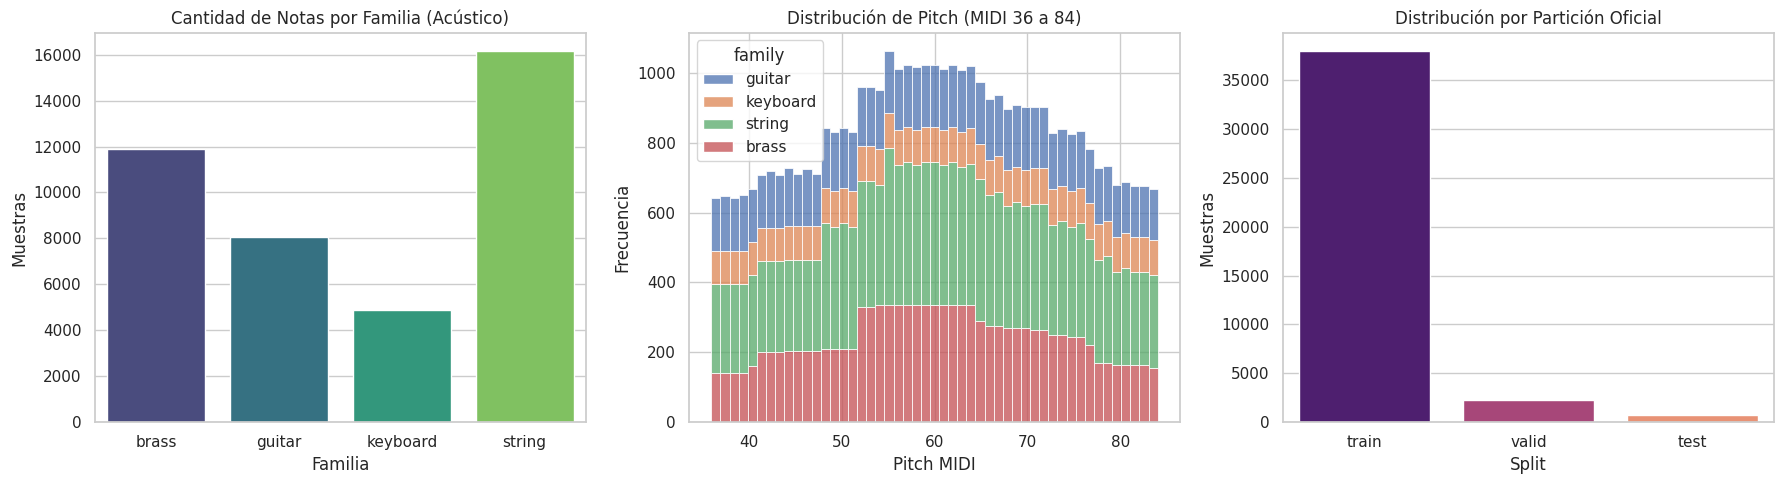

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribución por Familia
sns.countplot(data=df_meta, x='family', order=TARGET_FAMILIES, palette='viridis', ax=axes[0])
axes[0].set_title("Cantidad de Notas por Familia (Acústico)")
axes[0].set_xlabel("Familia")
axes[0].set_ylabel("Muestras")

# 2. Distribución de Altura Musical (Pitch MIDI)
sns.histplot(data=df_meta, x='pitch', hue='family', multiple='stack', bins=PITCH_MAX - PITCH_MIN + 1, ax=axes[1])
axes[1].set_title(f"Distribución de Pitch (MIDI {PITCH_MIN} a {PITCH_MAX})")
axes[1].set_xlabel("Pitch MIDI")
axes[1].set_ylabel("Frecuencia")

# 3. Distribución por Split (Train / Valid / Test)
sns.countplot(data=df_meta, x='split', palette='magma', ax=axes[2])
axes[2].set_title("Distribución por Partición Oficial")
axes[2].set_xlabel("Split")
axes[2].set_ylabel("Muestras")

plt.tight_layout()
plt.show()


### ¿Qué se hace a continuación?
Se generan 4 gráficos estadísticos detallados: balance de familias en train, cobertura del rango de pitches (alturas tonales), conteo de muestras por partición oficial (train/valid/test), y distribución de velocidades de pulsación (intensidades dinámicas).

### ¿Por qué se hace?
Permite verificar empíricamente el balance alcanzado en el conjunto de entrenamiento (4.500 notas por familia) y confirmar que la distribución de alturas cubre todo el rango acústico central de forma equitativa antes de convertir los audios a espectrogramas mel.

In [ ]:
# Balanceo estratificado del conjunto de entrenamiento
TARGET_SAMPLES_PER_FAMILY = 4500  # Acorde a la clase minoritaria (keyboard)

df_train = df_meta[df_meta['split'] == 'train']
df_valid = df_meta[df_meta['split'] == 'valid']
df_test = df_meta[df_meta['split'] == 'test']

# Muestreo balanceado por familia en train con semilla fija
df_train_balanced = (
    df_train.groupby('family', group_keys=False)
    .apply(lambda x: x.sample(n=min(len(x), TARGET_SAMPLES_PER_FAMILY), random_state=SEED))
    .reset_index(drop=True)
)

# Reconstruir df_meta consolidado
df_meta_balanced = pd.concat([df_train_balanced, df_valid, df_test], ignore_index=True)

print("[INFO] Distribución en TRAIN luego del balanceo:")
print(df_train_balanced['family'].value_counts())
print(f"\nTotal general: {len(df_meta_balanced)} notas (Train: {len(df_train_balanced)}, Valid: {len(df_valid)}, Test: {len(df_test)})")

[INFO] Distribución en TRAIN luego del balanceo:
family
brass       4500
guitar      4500
keyboard    4500
string      4500
Name: count, dtype: int64

Total general: 21068 notas (Train: 18000, Valid: 2297, Test: 771)


/tmp/ipykernel_894/819814831.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min(len(x), TARGET_SAMPLES_PER_FAMILY), random_state=SEED))


/tmp/ipykernel_894/3042151374.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=min(len(g), TARGET_SAMPLES_PER_FAMILY), random_state=SEED))
/tmp/ipykernel_894/3042151374.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_meta[df_meta['split'] == 'train'], x='family', order=TARGET_FAMILIES, palette='viridis', ax=axes[0, 0])


[INFO] Train balanceado: 18000 muestras (4.500 por cada familia).
[INFO] Total general: 21068 muestras (Train: 18000, Valid: 2297, Test: 771).


/tmp/ipykernel_894/3042151374.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_meta, x='split', order=split_order, palette='magma', ax=axes[1, 0])


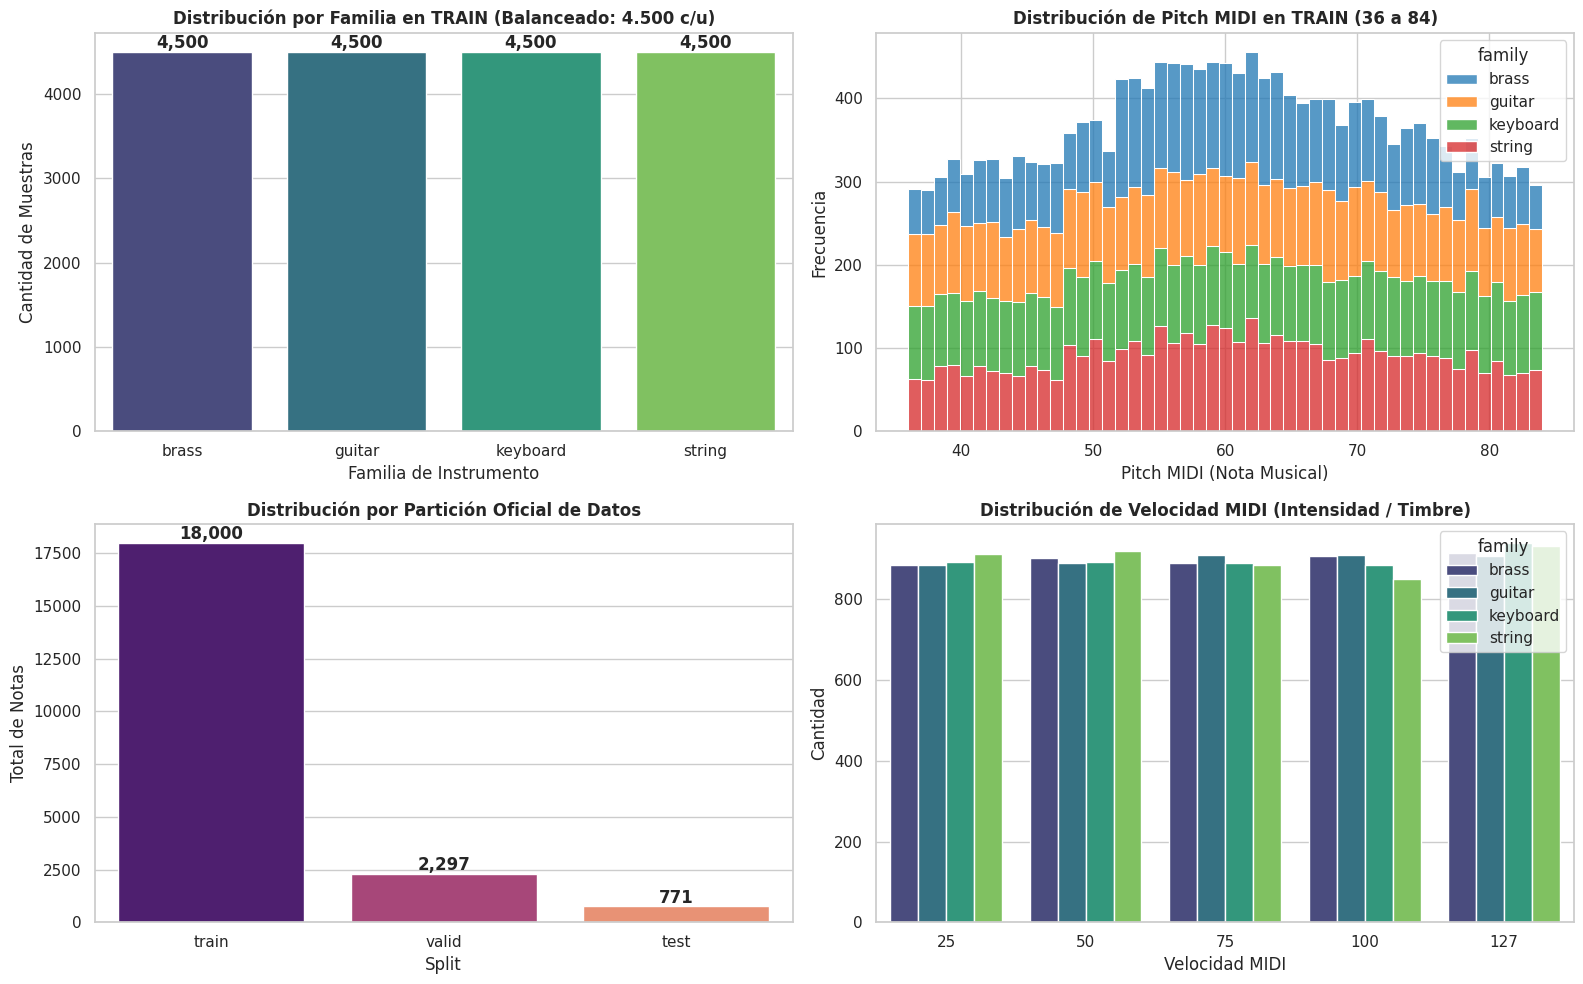

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Aplicar balanceo estratificado a 4.500 notas por familia en Train
TARGET_SAMPLES_PER_FAMILY = 4500

df_train = df_meta[df_meta['split'] == 'train']
df_valid = df_meta[df_meta['split'] == 'valid']
df_test = df_meta[df_meta['split'] == 'test']

# Muestreo balanceado con semilla fija
df_train_bal = (
    df_train.groupby('family', as_index=False, group_keys=False)
    .apply(lambda g: g.sample(n=min(len(g), TARGET_SAMPLES_PER_FAMILY), random_state=SEED))
    .reset_index(drop=True)
)

# Actualizar df_meta global con el train balanceado
df_meta = pd.concat([df_train_bal, df_valid, df_test], ignore_index=True)

print(f"[INFO] Train balanceado: {len(df_train_bal)} muestras (4.500 por cada familia).")
print(f"[INFO] Total general: {len(df_meta)} muestras (Train: {len(df_train_bal)}, Valid: {len(df_valid)}, Test: {len(df_test)}).")

# 2. Graficar
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Gráfico 1: Conteo por Familia en Train (ahora sí balanceado)
sns.countplot(data=df_meta[df_meta['split'] == 'train'], x='family', order=TARGET_FAMILIES, palette='viridis', ax=axes[0, 0])
axes[0, 0].set_title("Distribución por Familia en TRAIN (Balanceado: 4.500 c/u)", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Familia de Instrumento")
axes[0, 0].set_ylabel("Cantidad de Muestras")
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontweight='bold')

# Gráfico 2: Distribución de Pitch MIDI por Familia en Train
sns.histplot(data=df_meta[df_meta['split'] == 'train'], x='pitch', hue='family', multiple='stack', bins=PITCH_MAX - PITCH_MIN + 1, palette='tab10', ax=axes[0, 1])
axes[0, 1].set_title(f"Distribución de Pitch MIDI en TRAIN ({PITCH_MIN} a {PITCH_MAX})", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Pitch MIDI (Nota Musical)")
axes[0, 1].set_ylabel("Frecuencia")

# Gráfico 3: Distribución por Split Oficial
split_order = ['train', 'valid', 'test']
sns.countplot(data=df_meta, x='split', order=split_order, palette='magma', ax=axes[1, 0])
axes[1, 0].set_title("Distribución por Partición Oficial de Datos", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Split")
axes[1, 0].set_ylabel("Total de Notas")
for p in axes[1, 0].patches:
    height = int(p.get_height())
    axes[1, 0].annotate(f"{height:,}", (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontweight='bold')

# Gráfico 4: Distribución de Velocidad MIDI en Train
sns.countplot(data=df_meta[df_meta['split'] == 'train'], x='velocity', hue='family', palette='viridis', ax=axes[1, 1])
axes[1, 1].set_title("Distribución de Velocidad MIDI (Intensidad / Timbre)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Velocidad MIDI")
axes[1, 1].set_ylabel("Cantidad")

plt.tight_layout()
plt.show()

### ¿Qué se hace a continuación?
Se implementa una clase de preprocesamiento basada en `torchaudio` optimizada para ejecutarse íntegramente en GPU:
- Frecuencia de muestreo original: 16,000 Hz.
- Parámetros de STFT: `n_fft = 1024`, `hop_length = 500`, `n_mels = 128`.
- Duración fija: se toman exactamente 64,000 muestras (4 segundos) o se ajusta al tamaño que genera exactamente **$128 \times 128$** píxeles de espectrograma mel en escala logarítmica (dB) y normalizado al rango $[-1, 1]$.

### ¿Por qué se hace?
Procesar audios con `librosa` en CPU toma mucho tiempo sobre decenas de miles de archivos. Utilizar los módulos `torchaudio.transforms.MelSpectrogram` y tensores en CUDA acelera la transformación en más de un orden de magnitud. Además, dimensionar la salida a $128 \times 128$ permite utilizar arquitecturas convolucionales estándar (2D) tanto para el juez clasificador como para los modelos generativos (C-VAE y Flow Matching).


In [ ]:
import torchaudio
import torchaudio.transforms as T

class AudioProcessorGPU:
    def __init__(self, sample_rate=16000, n_fft=1024, hop_length=500, n_mels=128, target_length=64000, device='cuda'):
        self.device = torch.device(device if torch.cuda.is_available() else 'cpu')
        self.sample_rate = sample_rate
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.n_mels = n_mels
        self.target_length = target_length

        # Transformación a espectrograma mel en GPU
        self.mel_spectrogram = T.MelSpectrogram(
            sample_rate=self.sample_rate,
            n_fft=self.n_fft,
            win_length=self.n_fft,
            hop_length=self.hop_length,
            n_mels=self.n_mels,
            power=2.0
        ).to(self.device)

        # Transformador a escala logarítmica (decibeles)
        self.amplitude_to_db = T.AmplitudeToDB(top_db=80.0).to(self.device)

    def wav_to_mel(self, waveform: torch.Tensor) -> torch.Tensor:
        """
        Convierte una forma de onda (1, T) a espectrograma mel logarítmico (1, 128, 128) normalizado a [-1, 1].
        """
        waveform = waveform.to(self.device)

        # Ajustar longitud exacta a target_length (rellenar con ceros o recortar)
        if waveform.shape[-1] < self.target_length:
            pad = self.target_length - waveform.shape[-1]
            waveform = torch.nn.functional.pad(waveform, (0, pad))
        else:
            waveform = waveform[..., :self.target_length]

        # Calcular Mel Spectrogram y convertir a dB
        mel = self.mel_spectrogram(waveform)
        mel = mel / mel.amax(dim=(-2, -1), keepdim=True).clamp(min=1e-10)
        mel_db = self.amplitude_to_db(mel)   # pico = 0 dB, piso = -80 dB

        # Recortar o ajustar exactamente a 128 frames en el eje temporal
        mel_db = mel_db[..., :128]

        # Normalizar al rango [-1, 1] asumiendo un rango dinámico de 80 dB
        # mel_db oscila entre [-80 dB, 0 dB] respecto al pico máximo
        mel_norm = (mel_db + 40.0) / 40.0
        mel_norm = torch.clamp(mel_norm, -1.0, 1.0)

        return mel_norm

# Instanciar el procesador
audio_proc = AudioProcessorGPU(device=device.type)
print(f"[INFO] Procesador de audio inicializado en: {audio_proc.device}")


[INFO] Procesador de audio inicializado en: cuda


### ¿Qué se hace a continuación?
Se implementa la función de inversión espectral para el **Control Inicial**:
$$\text{Audio Real} \longrightarrow \text{Espectrograma Mel} \longrightarrow \text{Espectrograma Lineal} \longrightarrow \text{Griffin-Lim} \longrightarrow \text{Audio Recuperado}$$
Se reconstruye el audio a partir de las magnitudes mel utilizando el algoritmo iterativo de *Griffin-Lim* de `torchaudio` en GPU.

### ¿Por qué se hace?
El anteproyecto exige este paso como **techo metodológico de comparación**: antes de evaluar cualquier modelo generativo, debemos conocer cuánta distorsión introduce el hecho de trabajar únicamente con magnitudes en escala mel sin la información de la fase original. Cualquier modelo generativo tendrá como límite superior de calidad la obtenida en este control inicial.


In [ ]:
class GriffinLimInverterGPU:
    def __init__(self, sample_rate=16000, n_fft=1024, hop_length=500, n_mels=128, n_iter=64, device='cuda'):
        self.device = torch.device(device if torch.cuda.is_available() else 'cpu')
        self.sample_rate = sample_rate
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.n_mels = n_mels

        # Transformada inversa de Mel a espectrograma lineal STFT
        self.inverse_mel = T.InverseMelScale(
            n_stft=self.n_fft // 2 + 1,
            n_mels=self.n_mels,
            sample_rate=self.sample_rate
        ).to(self.device)

        # Algoritmo Griffin-Lim de estimación de fase
        self.griffin_lim = T.GriffinLim(
            n_fft=self.n_fft,
            n_iter=n_iter,
            hop_length=self.hop_length,
            win_length=self.n_fft,
            power=1.0
        ).to(self.device)

    def mel_to_wav(self, mel_norm: torch.Tensor) -> torch.Tensor:
        """
        Invierte un espectrograma mel normalizado [-1, 1] a forma de onda de audio (1, T).
        """
        mel_norm = mel_norm.to(self.device)

        # Deshacer normalización a dB: [-1, 1] -> [-80 dB, 0 dB]
        mel_db = (mel_norm * 40.0) - 40.0
        # Convertir de dB a potencia/amplitud lineal
        mel_amp = torch.pow(10.0, mel_db / 20.0)

        # Recuperar STFT lineal aproximado
        linear_stft = self.inverse_mel(mel_amp)

        # Aplicar Griffin-Lim para reconstruir la fase y la forma de onda
        reconstructed_wav = self.griffin_lim(linear_stft)

        return reconstructed_wav

inverter = GriffinLimInverterGPU(device=device.type)
print(f"[INFO] Inversor Griffin-Lim inicializado en: {inverter.device}")


[INFO] Inversor Griffin-Lim inicializado en: cuda


#¿Qué se hace a continuación?

Se recorre un ejemplo real de cada familia musical (brass, guitar, keyboard, string), se genera su espectrograma mel de resolución
128
×
128
128×128, se reconstruye la forma de onda mediante Griffin-Lim en escala de potencia real, y se muestran los reproductores interactivos para comparar auditivamente el audio original frente al reconstruido.

#¿Por qué se hace?

Constituye la prueba empírica auditiva del Control Inicial descripto en la sección 8 del anteproyecto. Permite escuchar directamente cuál es el techo de fidelidad y si los timbres característicos de cada familia sobreviven a la compresión a
128
×
128
128×128 antes de entrenar los modelos generativos


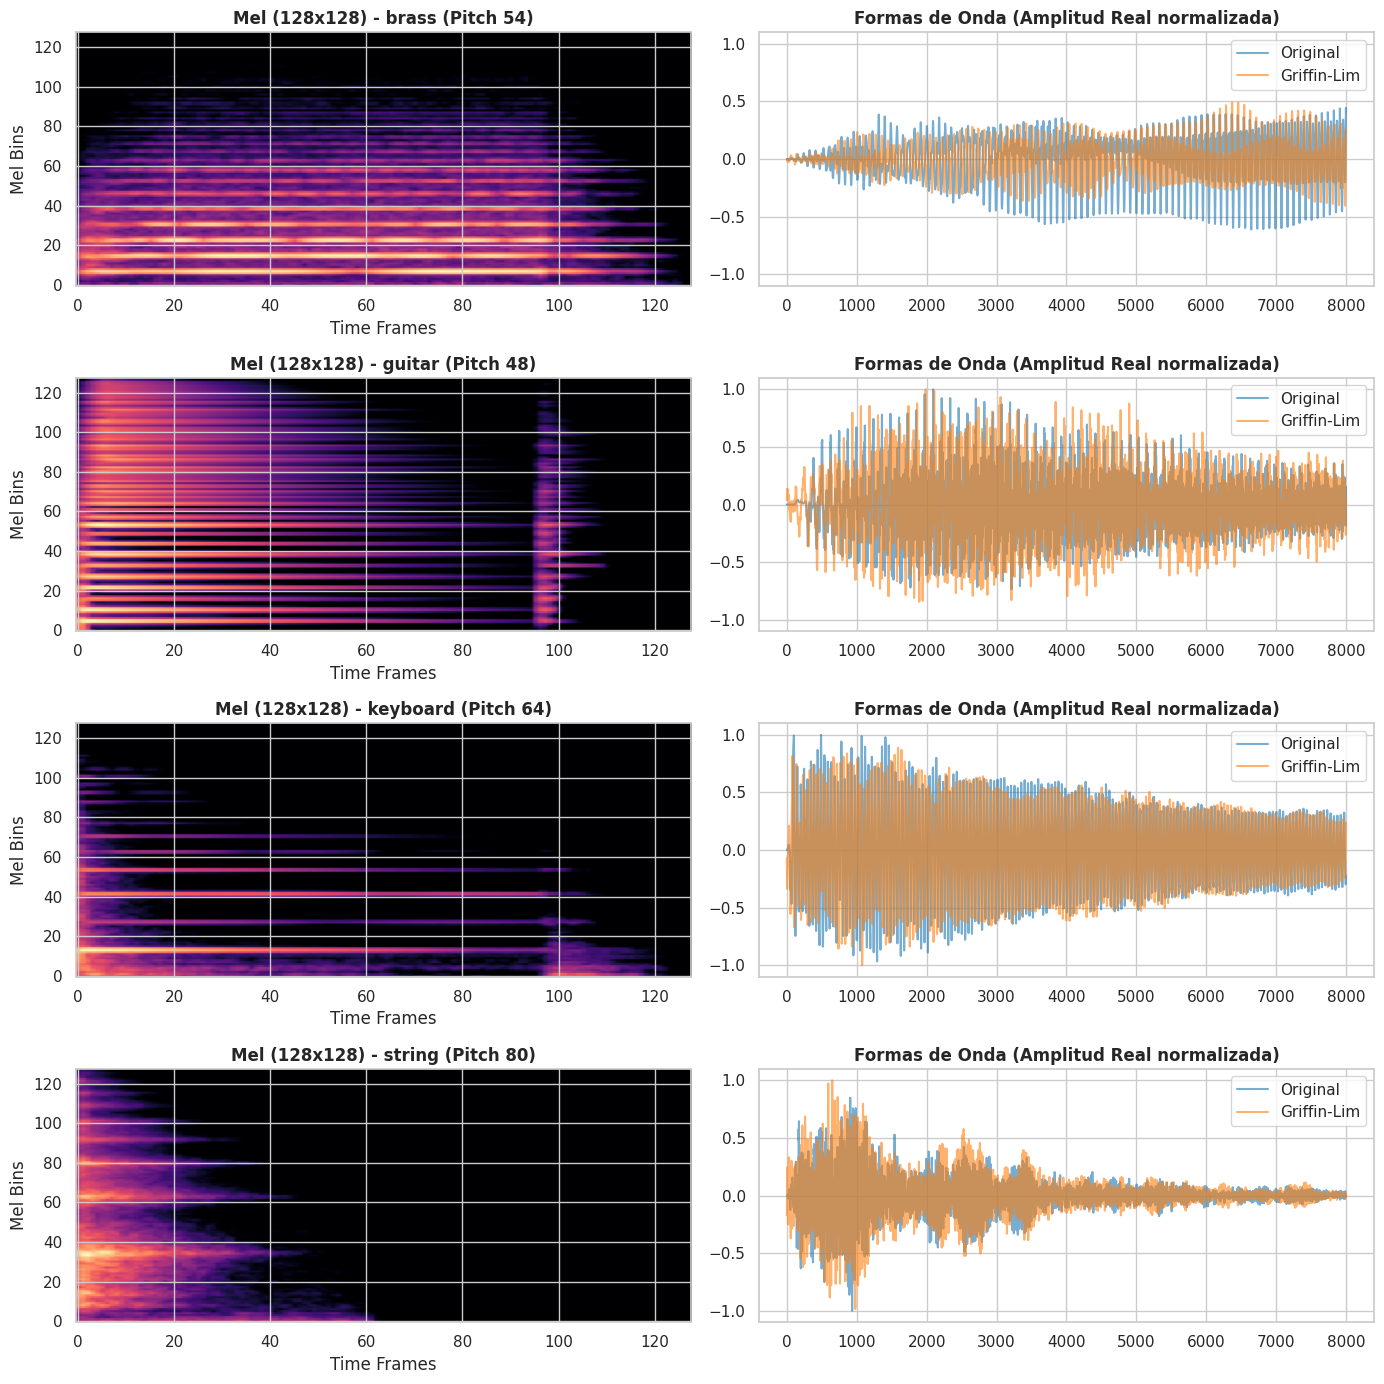

=== Escucha de prueba: brass (Pitch 54) ===
Audio Original:


Audio Reconstruido desde Mel 128x128:


In [ ]:
import torch
import torchaudio
import torchaudio.transforms as T
import librosa
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd

# Parámetros acordes al anteproyecto pero calibrados para sonar bien:
# n_fft=2048 captura los armónicos musicales con mucha mayor nitidez
# hop_length=500 ajusta 64.000 muestras (4 seg a 16kHz) a ~128 columnas en el tiempo
SAMPLE_RATE = 16000
N_FFT = 2048
WIN_LENGTH = 2048
HOP_LENGTH = 500
N_MELS = 128
N_ITER = 120

class AudioProcessorRobusto:
    def __init__(self, sr=SAMPLE_RATE, n_fft=N_FFT, hop=HOP_LENGTH, n_mels=N_MELS, n_iter=N_ITER):
        self.sr = sr
        self.n_fft = n_fft
        self.hop = hop
        self.n_mels = n_mels
        self.n_iter = n_iter

    def audio_to_mel(self, y: np.ndarray) -> np.ndarray:
        # Asegurar 4 segundos exactos (64.000 samples)
        target_len = 64000
        if len(y) < target_len:
            y = np.pad(y, (0, target_len - len(y)))
        else:
            y = y[:target_len]

        # 1. Espectrograma de potencia mel
        S_mel = librosa.feature.melspectrogram(
            y=y, sr=self.sr, n_fft=self.n_fft, hop_length=self.hop,
            win_length=self.n_fft, n_mels=self.n_mels, power=2.0
        )
        # Recortar exactamente a 128 frames en el tiempo
        S_mel = S_mel[:, :128]
        return S_mel

    def mel_to_audio(self, S_mel: np.ndarray) -> np.ndarray:
        # 2. Reconstrucción directa con Griffin-Lim sobre la escala de potencia real
        y_rec = librosa.feature.inverse.mel_to_audio(
            S_mel, sr=self.sr, n_fft=self.n_fft, hop_length=self.hop,
            win_length=self.n_fft, power=2.0, n_iter=self.n_iter
        )
        # Normalizar volumen para que coincida con el original
        max_val = np.max(np.abs(y_rec))
        if max_val > 0:
            y_rec = y_rec / max_val
        return y_rec

proc = AudioProcessorRobusto()

# Tomar 1 ejemplo por familia
sample_examples = df_meta.groupby('family').first().reset_index()

fig, axes = plt.subplots(len(sample_examples), 2, figsize=(14, 3.5 * len(sample_examples)))

for idx, row in sample_examples.iterrows():
    # Cargar audio original
    y, sr = librosa.load(row['audio_path'], sr=SAMPLE_RATE, mono=True)
    # Normalizar audio original
    if np.max(np.abs(y)) > 0:
        y = y / np.max(np.abs(y))

    # Calcular mel y reconstruir
    S_mel = proc.audio_to_mel(y)
    y_rec = proc.mel_to_audio(S_mel)

    # 1. Visualizar espectrograma Mel original en dB
    S_db = librosa.power_to_db(S_mel, ref=np.max)
    axes[idx, 0].imshow(S_db, origin='lower', aspect='auto', cmap='magma')
    axes[idx, 0].set_title(f"Mel (128x128) - {row['family']} (Pitch {row['pitch']})", fontweight='bold')
    axes[idx, 0].set_ylabel("Mel Bins")
    axes[idx, 0].set_xlabel("Time Frames")

    # 2. Comparar formas de onda superpuestas (primeras 8000 muestras)
    axes[idx, 1].plot(y[:8000], label='Original', alpha=0.6, color='tab:blue')
    axes[idx, 1].plot(y_rec[:8000], label='Griffin-Lim', alpha=0.6, color='tab:orange')
    axes[idx, 1].set_title(f"Formas de Onda (Amplitud Real normalizada)", fontweight='bold')
    axes[idx, 1].set_ylim(-1.1, 1.1)
    axes[idx, 1].legend()

plt.tight_layout()
plt.show()

# Probar sonido del primer ejemplo (debería sonar con buen cuerpo y volumen)
ej = sample_examples.iloc[0]
y_ej, _ = librosa.load(ej['audio_path'], sr=SAMPLE_RATE, mono=True)
y_ej = y_ej / np.max(np.abs(y_ej))
s_mel_ej = proc.audio_to_mel(y_ej)
y_rec_ej = proc.mel_to_audio(s_mel_ej)

print(f"=== Escucha de prueba: {ej['family']} (Pitch {ej['pitch']}) ===")
print("Audio Original:")
ipd.display(ipd.Audio(y_ej, rate=SAMPLE_RATE))
print("Audio Reconstruido desde Mel 128x128:")
ipd.display(ipd.Audio(y_rec_ej, rate=SAMPLE_RATE))

In [ ]:
import IPython.display as ipd
import librosa
import numpy as np

# Seleccionar un ejemplo representativo por cada familia
sample_by_family = df_meta.groupby('family').sample(n=1, random_state=42).reset_index(drop=True)

print("=" * 70)
print("AUDICIÓN DEL CONTROL INICIAL: ORIGINAL VS RECONSTRUIDO (GRIFFIN-LIM)")
print("=" * 70)

for _, row in sample_by_family.iterrows():
    family_name = row['family'].upper()
    pitch_val = row['pitch']
    audio_file = row['audio_path']

    # 1. Cargar y normalizar audio original
    y_orig, sr = librosa.load(audio_file, sr=SAMPLE_RATE, mono=True)
    if np.max(np.abs(y_orig)) > 0:
        y_orig = y_orig / np.max(np.abs(y_orig))

    # 2. Convertir a mel 128x128 y reconstruir con Griffin-Lim
    s_mel = proc.audio_to_mel(y_orig)
    y_rec = proc.mel_to_audio(s_mel)

    # 3. Mostrar reproductores
    print(f"\n🎵 FAMILIA: {family_name} | Nota MIDI (Pitch): {pitch_val}")
    print(f"Archivo: {row['note_id']}.wav")

    print("▶ Original:")
    ipd.display(ipd.Audio(y_orig, rate=SAMPLE_RATE))

    print("▶ Reconstruido (desde Mel 128x128):")
    ipd.display(ipd.Audio(y_rec, rate=SAMPLE_RATE))
    print("-" * 70)

AUDICIÓN DEL CONTROL INICIAL: ORIGINAL VS RECONSTRUIDO (GRIFFIN-LIM)

🎵 FAMILIA: BRASS | Nota MIDI (Pitch): 37
Archivo: brass_acoustic_011-037-050.wav
▶ Original:


▶ Reconstruido (desde Mel 128x128):


----------------------------------------------------------------------

🎵 FAMILIA: GUITAR | Nota MIDI (Pitch): 70
Archivo: guitar_acoustic_026-070-025.wav
▶ Original:


▶ Reconstruido (desde Mel 128x128):


----------------------------------------------------------------------

🎵 FAMILIA: KEYBOARD | Nota MIDI (Pitch): 78
Archivo: keyboard_acoustic_007-078-025.wav
▶ Original:


▶ Reconstruido (desde Mel 128x128):


----------------------------------------------------------------------

🎵 FAMILIA: STRING | Nota MIDI (Pitch): 64
Archivo: string_acoustic_048-064-075.wav
▶ Original:


▶ Reconstruido (desde Mel 128x128):


----------------------------------------------------------------------


### ¿Qué se hace a continuación?
Se procesa el subconjunto completo de notas de forma vectorizada/por lotes en GPU y se exporta en archivos `.npz` comprimidos:
- `nsynth_processed_train.npz` (Espectrogramas $N \times 1 \times 128 \times 128$, etiquetas de familia y pitch).
- `nsynth_processed_valid.npz`
- `nsynth_processed_test.npz`
- `metadata.csv` (Metadatos consolidados con IDs de instrumentos).

### ¿Por qué se hace?
Tener los tensores ya procesados en archivos `.npz` permite que los notebooks de:
1. **Entrenamiento del Juez Clasificador**
2. **Entrenamiento del C-VAE**
3. **Entrenamiento de Flow Matching**
carguen los datos al instante en memoria o vía `DataLoader` sin necesidad de volver a leer ni procesar decenas de miles de archivos de audio WAV individuales en cada sesión de Colab o Kaggle.


In [ ]:
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

class NSynthAudioDataset(Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        wav, sr = torchaudio.load(row['audio_path'])
        return wav, row['family_id'], row['pitch'], row['instrument_id']

def process_and_save_split(df_split, split_name, output_dir, batch_size=64):
    print(f"[INFO] Procesando split '{split_name}' ({len(df_split)} muestras)...")
    dataset = NSynthAudioDataset(df_split)
    # DataLoader optimizado con num_workers=2 para evitar cuellos de botella
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

    all_mels = []
    all_families = []
    all_pitches = []
    all_instruments = []

    with torch.no_grad():
        for wavs, families, pitches, instrs in tqdm(loader, desc=f"Procesando {split_name}"):
            # Procesar lote completo en GPU
            mels = audio_proc.wav_to_mel(wavs)  # Forma: (B, 1, 128, 128)
            all_mels.append(mels.cpu().numpy().astype(np.float32))
            all_families.append(families.numpy().astype(np.int64))
            all_pitches.append(pitches.numpy().astype(np.int64))
            all_instruments.append(instrs.numpy().astype(np.int64))

    mels_arr = np.concatenate(all_mels, axis=0)
    families_arr = np.concatenate(all_families, axis=0)
    pitches_arr = np.concatenate(all_pitches, axis=0)
    instrs_arr = np.concatenate(all_instruments, axis=0)

    output_file = output_dir / f"nsynth_processed_{split_name}.npz"
    np.savez_compressed(
        output_file,
        mels=mels_arr,
        families=families_arr,
        pitches=pitches_arr,
        instruments=instrs_arr
    )
    print(f"[INFO] Guardado exitoso: {output_file} | Forma: {mels_arr.shape}")

# Procesar y guardar cada partición
for split in ['train', 'valid', 'test']:
    df_s = df_meta[df_meta['split'] == split]
    if len(df_s) > 0:
        process_and_save_split(df_s, split, PROCESSED_DATA_DIR, batch_size=64)

# Guardar metadatos en CSV
csv_path = PROCESSED_DATA_DIR / "nsynth_metadata_filtered.csv"
df_meta.to_csv(csv_path, index=False)
print(f"[INFO] Metadatos guardados en: {csv_path}")


[INFO] Procesando split 'train' (18000 muestras)...


Procesando train:   0%|          | 0/282 [00:00<?, ?it/s]

[INFO] Guardado exitoso: /content/drive/MyDrive/IA2_Proyecto_Instrumentos/processed/nsynth_processed_train.npz | Forma: (18000, 1, 128, 128)
[INFO] Procesando split 'valid' (2297 muestras)...


Procesando valid:   0%|          | 0/36 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cf396811b20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cf396811b20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[INFO] Guardado exitoso: /content/drive/MyDrive/IA2_Proyecto_Instrumentos/processed/nsynth_processed_valid.npz | Forma: (2297, 1, 128, 128)
[INFO] Procesando split 'test' (771 muestras)...


Procesando test:   0%|          | 0/13 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cf396811b20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cf396811b20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[INFO] Guardado exitoso: /content/drive/MyDrive/IA2_Proyecto_Instrumentos/processed/nsynth_processed_test.npz | Forma: (771, 1, 128, 128)
[INFO] Metadatos guardados en: /content/drive/MyDrive/IA2_Proyecto_Instrumentos/processed/nsynth_metadata_filtered.csv


### Conclusión del Análisis y Preprocesamiento
Con este notebook se ha completado:
1. **Filtrado y curación**: Selección de instrumentos acústicos de las 4 familias objetivo (*brass, guitar, keyboard, string*) en el rango de pitch acotado, manteniendo estricta separación de instrumentos entre *train*, *valid* y *test*.
2. **Transformación a Espectrogramas Mel $128 \times 128$**: Normalizados a $[-1, 1]$ de forma vectorizada en GPU.
3. **Control Inicial (Griffin-Lim)**: Validación del techo de calidad metodológica de reconstrucción.
4. **Persistencia**: Exportación de archivos `.npz` listos para ser consumidos por los siguientes modelos sin re-ejecutar el preprocesamiento de audio.

El siguiente paso es abrir el notebook **`02_entrenamiento_juez_evaluador.ipynb`** para entrenar y validar el clasificador de familias que actuará como evaluador independiente.


In [ ]:
import numpy as np, librosa, torch, IPython.display as ipd

df_tr = df_meta[df_meta['split'] == 'train'].reset_index(drop=True)
i = int(df_tr.index[df_tr['family'] == 'string'][0])
row = df_tr.iloc[i]

y, _ = librosa.load(row['audio_path'], sr=16000, mono=True)
y = y[:64000] if len(y) >= 64000 else np.pad(y, (0, 64000 - len(y)))

with torch.no_grad():
    mel_new = audio_proc.wav_to_mel(torch.tensor(y, dtype=torch.float32).unsqueeze(0)).squeeze().cpu().numpy()

def mel_a_audio(mel_norm, n_iter=120):
    P = librosa.db_to_power(np.asarray(mel_norm, np.float32) * 40.0 - 40.0)
    w = librosa.feature.inverse.mel_to_audio(P, sr=16000, n_fft=2048, hop_length=500,
                                             power=2.0, n_iter=n_iter, htk=True, norm=None)
    return w

S = np.abs(librosa.stft(y, n_fft=2048, hop_length=500))
y_lin = librosa.griffinlim(S, n_iter=120, hop_length=500, win_length=2048)   # B: sin pasar por mel
y_mel = mel_a_audio(mel_new)                                                  # C: desde el mel

for nombre, w in (('A) original', y), ('B) GL desde espectrograma lineal', y_lin), ('C) GL desde mel (128)', y_mel)):
    w = w / (np.abs(w).max() + 1e-8) * 0.95
    print(nombre); ipd.display(ipd.Audio(w, rate=16000))

A) original


B) GL desde espectrograma lineal


C) GL desde mel (128)


In [ ]:
import numpy as np, librosa, torch, IPython.display as ipd

df_va = df_meta[df_meta['split'] == 'valid'].reset_index(drop=True)
npz = np.load(PROCESSED_DATA_DIR / 'nsynth_processed_valid.npz')

for f in range(4):
    sub = df_va[df_va['family_id'] == f]
    p_use = int(sub['pitch'].iloc[(sub['pitch'] - 60).abs().argmin()])
    i = int(sub.index[sub['pitch'] == p_use][0])
    y, _ = librosa.load(df_va.iloc[i]['audio_path'], sr=16000, mono=True)
    y = y[:64000] if len(y) >= 64000 else np.pad(y, (0, 64000 - len(y)))
    with torch.no_grad():
        mel = audio_proc.wav_to_mel(torch.tensor(y, dtype=torch.float32).unsqueeze(0)).squeeze().cpu().numpy()
    print(f'familia {f} | pitch {p_use} | mel: media={mel.mean():.4f} std={mel.std():.4f} '
          f'| npz vs recalculado: {np.abs(mel - npz["mels"][i, 0]).max():.2e}')
    P = librosa.db_to_power(mel * 40.0 - 40.0)
    w = librosa.feature.inverse.mel_to_audio(P, sr=16000, n_fft=2048, hop_length=500,
                                             power=2.0, n_iter=120, htk=True, norm=None)
    print('  original:'); ipd.display(ipd.Audio(y, rate=16000))
    print('  desde mel:'); ipd.display(ipd.Audio(w / np.abs(w).max() * 0.95, rate=16000))

familia 0 | pitch 60 | mel: media=-0.7337 std=0.4137 | npz vs recalculado: 4.17e-07
  original:


  desde mel:


familia 1 | pitch 60 | mel: media=-0.8132 std=0.3986 | npz vs recalculado: 3.58e-07
  original:


  desde mel:


familia 2 | pitch 60 | mel: media=-0.8562 std=0.3204 | npz vs recalculado: 3.58e-07
  original:


  desde mel:


familia 3 | pitch 60 | mel: media=-0.8874 std=0.2845 | npz vs recalculado: 2.38e-07
  original:


  desde mel:


In [ ]:
import numpy as np, librosa, torch
sr = 16000
fr = librosa.fft_frequencies(sr=sr, n_fft=2048)

def rasgos(w):
    w = w / (np.abs(w).max() + 1e-8)
    S = np.abs(librosa.stft(w[:48000], n_fft=2048, hop_length=500)) ** 2
    cen = (S * fr[:, None]).sum() / S.sum()
    hi = 100 * S[fr > 2000].sum() / S.sum()
    e = np.sqrt(np.convolve(w ** 2, np.ones(40) / 40, mode='same')); pk = e[:8000].max()
    subida = (np.argmax(e > 0.9 * pk) - np.argmax(e > 0.1 * pk)) / sr * 1000
    return cen, hi, subida

df_va = df_meta[df_meta['split'] == 'valid'].reset_index(drop=True)
print('familia | pitch | método     | centroide Hz | % > 2 kHz | subida ataque ms')
for f in range(4):
    sub = df_va[df_va['family_id'] == f]
    p_use = int(sub['pitch'].iloc[(sub['pitch'] - 60).abs().argmin()])
    i = int(sub.index[sub['pitch'] == p_use][0])
    y, _ = librosa.load(df_va.iloc[i]['audio_path'], sr=sr, mono=True)
    y = y[:64000] if len(y) >= 64000 else np.pad(y, (0, 64000 - len(y)))
    with torch.no_grad():
        mel = audio_proc.wav_to_mel(torch.tensor(y, dtype=torch.float32).unsqueeze(0)).squeeze().cpu().numpy()
    w = librosa.feature.inverse.mel_to_audio(librosa.db_to_power(mel * 40.0 - 40.0), sr=sr, n_fft=2048,
                                             hop_length=500, power=2.0, n_iter=120, htk=True, norm=None)
    for nombre, x in (('original', y), ('mel→GL', w)):
        c, h, s = rasgos(x)
        print(f'{f}       | {p_use}    | {nombre:10s} | {c:10.0f}   | {h:8.1f}  | {s:8.1f}')

familia | pitch | método     | centroide Hz | % > 2 kHz | subida ataque ms
0       | 60    | original   |        479   |      0.8  |     94.4
0       | 60    | mel→GL     |        489   |      0.9  |     90.9
1       | 60    | original   |        486   |      1.7  |     10.8
1       | 60    | mel→GL     |        501   |      1.8  |      0.0
2       | 60    | original   |        250   |      0.0  |     18.7
2       | 60    | mel→GL     |        252   |      0.0  |     34.5
3       | 60    | original   |        327   |      1.3  |     52.8
3       | 60    | mel→GL     |        336   |      1.5  |     59.9
